# Cross-Domain User Preference Modeling Using Social Network Embeddings

This notebook contains the complete experimental pipeline for personalized recommendation using SocialVec embeddings. We evaluate recommendation performance across 14 topical categories using ~12,000 Twitter users and compare multiple approaches including social embeddings, popularity baselines, and LLM-based methods.

In [ ]:
%autoreload 2
%reload_ext autoreload

In [ ]:
import pandas as pd
from tqdm.notebook import tqdm
import ast
tqdm.pandas()
from socialvec.socialvec import SocialVec
import random
import numpy as np
from scipy.spatial.distance import cosine
from typing import List, Tuple, Dict

from data_utils import (
    get_relevant_subset_users,
    find_number_of_categories_per_user,
    seperate_topic_accounts,
    prepare_df_for_topic
)
from ranking import (
    get_sv_rank,
    get_popular_rank,
    reset_and_rank_topic_accounts
)
from visualization_utils import create_manual_radar_plot

In [ ]:
all_topics = pd.read_excel("../data/popular_accounts_manually_validated.xlsx", sheet_name=None)
df_users = pd.read_pickle("../data/users_selected_for_the_experiment2.pkl")


In [ ]:
df_users['friends_count'] = df_users['friends_count'].astype(int)
df_users[df_users['friends_count']!=0]['friends_count'].describe().apply(lambda x: format(x, ',.02f'))

count    13,798.00
mean      1,754.86
std       1,428.83
min           1.00
25%         603.00
50%       1,289.00
75%       2,559.00
max       5,000.00
Name: friends_count, dtype: object

In [92]:
df_users = df_users[~df_users['account_selected_for'].isna()]

In [93]:
df_accounts = pd.DataFrame()

for i in all_topics:
    all_topics[i] = all_topics[i][all_topics[i]['use']==1].copy()
    df_accounts = pd.concat([df_accounts, all_topics[i]])

df_accounts = df_accounts[df_accounts['use']==1]
df_accounts['twitter_user_id'] = df_accounts['twitter_user_id'].astype(int)
df_accounts.drop(df_accounts.columns[df_accounts.columns.str.contains('unnamed',case = False)],axis = 1, inplace = True)

In [94]:
df_accounts['followers_count'].describe().apply(lambda x: format(x, ',.02f'))

count            276.00
mean       8,366,736.22
std       18,025,941.11
min           20,642.00
25%          510,939.00
50%        1,873,836.00
75%        6,500,807.50
max      115,819,215.00
Name: followers_count, dtype: object

In [97]:
account_list = df_accounts['twitter_user_id'].values
topic_list = [t for t in all_topics]

In [98]:
#keep only users with the relevant topics (since we removed some)
print(df_users.shape[0])
df_users = df_users[df_users['topic'].isin(topic_list)]
print(df_users.shape[0])

13800
13800


In [ ]:
df_users["number_of_accounts_full_sv"] = df_users["friends_ids"].apply(lambda x: len(x))
df_users["experiment_accounts"] = df_users["friends_ids"].apply(lambda x: get_relevant_subset_users(x, account_list))
df_users["number_of_accounts_from_experiment"] = df_users["experiment_accounts"].apply(lambda x: len(x))

In [101]:
df_users["number_of_accounts_from_experiment"].describe().apply(lambda x: format(x, ',.02f'))

count    13,800.00
mean         33.74
std          25.69
min           1.00
25%          13.00
50%          27.00
75%          49.00
max         170.00
Name: number_of_accounts_from_experiment, dtype: object

In [102]:
minimal_number_of_accounts = 10

number_of_users_before_filtering = df_users.shape[0]
df_users = df_users[df_users["number_of_accounts_from_experiment"]>minimal_number_of_accounts]
print(f"removed {number_of_users_before_filtering - df_users.shape[0]} users in order to use only users who follow more than {minimal_number_of_accounts} users")
print(f"Using {df_users.shape[0]/number_of_users_before_filtering:.0%} of the users")

removed 2647 users in order to use only users who follow more than 10 users
Using 81% of the users


In [105]:
sv = SocialVec()

✅  Initializing Model
✅  Load Metadata


In [ ]:
df_users["experiment_accounts_str"] = df_users["experiment_accounts"].progress_apply(lambda x: [str(i) for i in x])

## 1. Pre-calculate Embeddings
Compute SocialVec embeddings for all topic accounts once to optimize performance.

In [110]:
# Calculate Topics SV
for topic in topic_list:
    #all_topics[topic]['twitter_user_id'] = all_topics[topic]['twitter_user_id'].astype(int).astype(str)
    all_topics[topic]['account_sv'] = all_topics[topic]['twitter_user_id'].apply(lambda x: sv[x])

In [114]:
def list_str(my_list):
    return [str(i) for i in my_list]

## 2. Pre-process All Topics
Loop through all topics and prepare the dataframes for each category using utility functions.

In [ ]:
df_for_all_topic = {}
for topic in (pbar := tqdm(topic_list)):
    pbar.set_description(f"Preparing topic {topic}")
    df_for_all_topic[topic] = prepare_df_for_topic(topic, df_users, all_topics)

In [ ]:
df_stats = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    #pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic].copy()
    
    df_for_topic['number_of_non_topic_accounts'] = df_for_topic['non_topic_accounts'].apply(lambda x: len(x))
    df_for_topic['number_of_topic_accounts'] = df_for_topic['topic_accounts'].apply(lambda x: len(x))
    df_for_topic['topic'] = topic
    
    df_stats = pd.concat([df_stats,df_for_topic])

In [ ]:
pd.options.display.float_format = "{:,.2f}".format

In [ ]:
df_stats[['topic','friends_ids_len',
              'number_of_accounts_from_experiment',
              'number_of_categories_this_user_follows',
              'number_of_non_topic_accounts',
              'number_of_topic_accounts' ]].describe().T


## 3. Mean Average Precision (MAP) Calculations - Limited World

Calculate MAP scores for the cold-start scenario where recommendations are limited to accounts within the experiment dataset. Compare three approaches:
1. **Full SocialVec**: Using all non-topic friends the user follows
2. **Sampled SocialVec**: Using random subsets (10-50 friends) to simulate cold-start
3. **Popularity Baseline**: Using follower counts as ranking signal

In [ ]:
map_all_topics = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic]
    map_result = pd.DataFrame()

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
        user_experiment_account_except_selected_accounts = user['non_topic_accounts_str']
        
        # Get SV rank when using all of the accounts that the user follows
        all_sv_rank = get_sv_rank(sv.get_average_embeddings(user_all_accounts_except_selected_accounts)[0],all_topics[topic])
        all_sv_rank = reset_and_rank_topic_accounts(all_sv_rank, user['topic_accounts'])
        
        # Try differet thresholds of 
        sample_result_data = {}
        for sample_size in [10, 20, 30, 40, 50]:
            if sample_size < len(user['non_topic_accounts']):
                random.seed(76)
                acounts_for_sample = random.sample(user['non_topic_accounts'],sample_size)
            else:
                acounts_for_sample = user['non_topic_accounts']
            sample_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(acounts_for_sample))[0],all_topics[topic])
            sample_sv_rank = reset_and_rank_topic_accounts(sample_sv_rank, user['topic_accounts'])
            sample_result_data[f"exp_sv_sample__{sample_size}_map"]= [(sample_sv_rank['index'] / sample_sv_rank['rank']).mean()]
        
        # Get SV rank when using only the accounts in the experiment (exculing the one of the selected topic)
        non_topic_accounts_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(user['non_topic_accounts']))[0],all_topics[topic])
        non_topic_accounts_sv_rank = reset_and_rank_topic_accounts(non_topic_accounts_sv_rank, user['topic_accounts'])
    
        # Get popularity rank
        user_popular_rank = get_popular_rank(all_topics[topic])
        user_popular_rank = reset_and_rank_topic_accounts(user_popular_rank, user['topic_accounts'])

        result_dict = {'user':[user['screen_name']],
                                         'fullsv_rank':[all_sv_rank['rank'].values],
                                         'fullsv_map':[(all_sv_rank['index'] / all_sv_rank['rank']).mean()],
                                         'experimantsv_rank':[non_topic_accounts_sv_rank['rank'].values],
                                         'experimantsv_map':[(non_topic_accounts_sv_rank['index'] / non_topic_accounts_sv_rank['rank']).mean()],
                                         'popular_rank': [user_popular_rank['rank'].values],
                                         'popular_map':[( user_popular_rank['index'] / user_popular_rank['rank']).mean()]
                                        }
        
        result = pd.DataFrame.from_dict(result_dict | sample_result_data)
        map_result = pd.concat([map_result,result])

    map_result['topic'] = topic
    map_all_topics = pd.concat([map_all_topics,map_result])


### MAP Metrics Explanation
- **fullsv_map**: Mean Average Precision using all friends' SV embeddings
- **experimantsv_map**: MAP using only experiment accounts (cold-start scenario)
- **exp_sv_sample__X_map**: MAP using only X sampled accounts from experiment

In [276]:
pd.set_option('display.float_format', '{:,.3f}'.format)
columns_to_show = [col for col in map_result.columns if 'map' in col]
threshold_restuls = map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()
threshold_restuls

,topic,fullsv_map,experimantsv_map,popular_map,exp_sv_sample__10_map,exp_sv_sample__20_map,exp_sv_sample__30_map,exp_sv_sample__40_map,exp_sv_sample__50_map
0,Actor,0.647,0.602,0.521,0.598,0.604,0.601,0.601,0.602
1,Comedian,0.599,0.594,0.545,0.584,0.590,0.593,0.594,0.594
2,Film,0.399,0.241,0.221,0.244,0.244,0.239,0.241,0.241
3,Journalist,0.675,0.640,0.622,0.640,0.640,0.640,0.640,0.640
4,MusicalArtist,0.633,0.591,0.520,0.584,0.589,0.591,0.591,0.592
5,Politician,0.777,0.755,0.720,0.754,0.756,0.755,0.755,0.755
6,Resturants,0.499,0.481,0.492,0.474,0.482,0.481,0.481,0.480
7,SportsTeam,0.510,0.385,0.349,0.381,0.386,0.385,0.385,0.386
8,TelevisionHost,0.428,0.394,0.301,0.389,0.390,0.394,0.393,0.394
9,TelevisionShow,0.635,0.551,0.365,0.532,0.549,0.551,0.549,0.550


In [50]:
df_users.groupby(by=['topic'])['number_of_accounts_full_sv'].describe()

,count,mean,std,min,25%,50%,75%,max
topic,,,,,,,,
Actor,809.000,"1,839.532","1,403.832",72.000,754.000,"1,325.000","2,665.000","4,999.000"
Comedian,854.000,"1,889.864","1,417.589",71.000,772.000,"1,433.500","2,629.000","4,999.000"
Film,741.000,"2,261.136","1,385.206",170.000,"1,136.000","1,946.000","3,186.000","4,999.000"
Journalist,948.000,"1,991.842","1,438.794",110.000,820.000,"1,573.500","2,886.250","4,999.000"
MusicalArtist,720.000,"1,677.001","1,385.077",82.000,597.750,"1,190.000","2,311.500","4,999.000"
Politician,804.000,"1,788.853","1,430.423",61.000,636.000,"1,300.500","2,627.250","4,999.000"
Resturants,803.000,"2,203.902","1,450.193",153.000,985.000,"1,874.000","3,200.500","4,999.000"
SportsTeam,691.000,"1,747.077","1,369.383",59.000,681.500,"1,330.000","2,445.500","4,999.000"
TelevisionHost,835.000,"2,255.048","1,458.516",110.000,"1,048.000","1,968.000","3,384.000","4,999.000"


In [ ]:
df_topic_accounts_count_stats = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    df_for_all_topic[topic]['topic_accounts_count'] = df_for_all_topic[topic]['topic_accounts'].apply(lambda x: len(x))
    df_topic_accounts_count_stats = pd.concat([df_topic_accounts_count_stats,
                                              df_for_all_topic[topic]['topic_accounts_count'].describe().to_frame().rename(columns={'topic_accounts_count':topic}).T])
    

In [218]:
df_topic_accounts_count_stats.reset_index(names=['topic']).sort_values(by=['topic'])

,topic,count,mean,std,min,25%,50%,75%,max
3,Actor,809.000,6.570,3.849,1.000,3.000,6.000,9.000,19.000
7,Comedian,854.000,6.841,4.094,1.000,3.000,6.000,10.000,19.000
9,Film,741.000,1.354,0.798,1.000,1.000,1.000,1.000,7.000
10,Journalist,948.000,10.064,5.298,1.000,6.000,10.000,15.000,19.000
1,MusicalArtist,720.000,7.628,4.547,1.000,4.000,7.000,11.000,20.000
4,Politician,804.000,11.164,4.581,1.000,8.000,12.000,15.000,19.000
0,Resturants,803.000,5.205,4.161,1.000,2.000,4.000,8.000,19.000
8,SportsTeam,691.000,4.288,4.197,1.000,1.000,2.000,6.000,20.000
11,TelevisionHost,835.000,1.844,1.101,1.000,1.000,1.000,2.000,8.000
5,TelevisionShow,773.000,3.909,2.557,1.000,2.000,3.000,5.000,13.000


In [278]:
map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()

,topic,fullsv_map,experimantsv_map,popular_map,exp_sv_sample__10_map,exp_sv_sample__20_map,exp_sv_sample__30_map,exp_sv_sample__40_map,exp_sv_sample__50_map
0,Actor,0.647,0.602,0.521,0.598,0.604,0.601,0.601,0.602
1,Comedian,0.599,0.594,0.545,0.584,0.590,0.593,0.594,0.594
2,Film,0.399,0.241,0.221,0.244,0.244,0.239,0.241,0.241
3,Journalist,0.675,0.640,0.622,0.640,0.640,0.640,0.640,0.640
4,MusicalArtist,0.633,0.591,0.520,0.584,0.589,0.591,0.591,0.592
5,Politician,0.777,0.755,0.720,0.754,0.756,0.755,0.755,0.755
6,Resturants,0.499,0.481,0.492,0.474,0.482,0.481,0.481,0.480
7,SportsTeam,0.510,0.385,0.349,0.381,0.386,0.385,0.385,0.386
8,TelevisionHost,0.428,0.394,0.301,0.389,0.390,0.394,0.393,0.394
9,TelevisionShow,0.635,0.551,0.365,0.532,0.549,0.551,0.549,0.550


## 4. Mean Average Precision (MAP) on All Accounts

Evaluate performance using the complete set of accounts the user follows (excluding target category). This tests generalization beyond the limited experiment dataset with increasing sample sizes (10 to 5000 accounts).

In [ ]:

map_all_topics = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    #pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic]
    map_result = pd.DataFrame()

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        
        # All accounts that the user follows except the ones from the topic...
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
        
        # Get SV rank when using all of the accounts that the user follows
        all_sv_rank = get_sv_rank(sv.get_average_embeddings(user_all_accounts_except_selected_accounts)[0],all_topics[topic])
        all_sv_rank = reset_and_rank_topic_accounts(all_sv_rank, user['topic_accounts'])
        
        # Try differet thresholds of 
        sample_result_data = {}
        for sample_size in [10, 20, 30, 40, 50, 80, 100, 300, 500, 5000]:
            if sample_size < len(user_all_accounts_except_selected_accounts):
                random.seed(76)
                acounts_for_sample = random.sample(user_all_accounts_except_selected_accounts,sample_size)
            else:
                acounts_for_sample = user_all_accounts_except_selected_accounts
                
            sample_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(acounts_for_sample))[0],all_topics[topic])
            sample_sv_rank = reset_and_rank_topic_accounts(sample_sv_rank, user['topic_accounts'])
            sample_result_data[f"exp_sv_sample__{sample_size}_map"]= [(sample_sv_rank['index'] / sample_sv_rank['rank']).mean()]
        
        # Get popularity rank
        user_popular_rank = get_popular_rank(all_topics[topic])
        user_popular_rank = reset_and_rank_topic_accounts(user_popular_rank, user['topic_accounts'])

        result_dict = {'user':[user['screen_name']],
                                         'fullsv_rank':[all_sv_rank['rank'].values],
                                         'fullsv_map':[(all_sv_rank['index'] / all_sv_rank['rank']).mean()],
#                                         'experimantsv_rank':[non_topic_accounts_sv_rank['rank'].values],
#                                         'experimantsv_map':[(non_topic_accounts_sv_rank['index'] / non_topic_accounts_sv_rank['rank']).mean()],
                                         'popular_rank': [user_popular_rank['rank'].values],
                                         'popular_map':[( user_popular_rank['index'] / user_popular_rank['rank']).mean()]
                                        }
        
        result = pd.DataFrame.from_dict(result_dict | sample_result_data)
        map_result = pd.concat([map_result,result])

    map_result['topic'] = topic
    map_all_topics = pd.concat([map_all_topics,map_result])


In [138]:
columns_to_show = [col for col in map_result.columns if 'map' in col]
threshold_restuls = map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()
threshold_restuls

,topic,fullsv_map,popular_map,exp_sv_sample__10_map,exp_sv_sample__20_map,exp_sv_sample__30_map,exp_sv_sample__40_map,exp_sv_sample__50_map,exp_sv_sample__80_map,exp_sv_sample__100_map,exp_sv_sample__300_map,exp_sv_sample__500_map,exp_sv_sample__5000_map
0,Actor,0.647,0.521,0.609,0.623,0.632,0.635,0.637,0.641,0.642,0.648,0.649,0.647
1,Comedian,0.599,0.545,0.573,0.581,0.587,0.591,0.593,0.597,0.599,0.601,0.598,0.599
2,Film,0.399,0.221,0.341,0.356,0.368,0.375,0.372,0.393,0.398,0.397,0.401,0.399
3,Journalist,0.675,0.622,0.641,0.655,0.663,0.665,0.668,0.670,0.671,0.672,0.674,0.675
4,MusicalArtist,0.633,0.520,0.603,0.613,0.622,0.628,0.625,0.629,0.629,0.633,0.632,0.633
5,Politician,0.777,0.720,0.753,0.764,0.769,0.769,0.774,0.774,0.776,0.777,0.777,0.777
6,Resturants,0.499,0.492,0.470,0.485,0.482,0.485,0.485,0.490,0.490,0.496,0.496,0.499
7,SportsTeam,0.510,0.349,0.463,0.471,0.484,0.493,0.495,0.503,0.506,0.509,0.510,0.510
8,TelevisionHost,0.428,0.301,0.379,0.414,0.416,0.426,0.422,0.425,0.422,0.427,0.431,0.428
9,TelevisionShow,0.635,0.365,0.566,0.597,0.612,0.618,0.622,0.625,0.624,0.631,0.635,0.635


## 5. TSNE Visualization (Embeddings Projector)

Generate data files for TensorBoard's Embeddings Projector to visualize the 100-dimensional SocialVec embeddings in 2D/3D space.

### Generate TensorBoard Files
Create vectors.tsv and metadata.tsv for interactive embedding exploration.

In [34]:
import csv
import os
import numpy as np

# Define output paths
output_dir = 'outputs'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

vectors_path = os.path.join(output_dir, 'vectors.tsv')
metadata_path = os.path.join(output_dir, 'metadata.tsv')

with open(vectors_path, 'w', newline='', encoding='utf-8') as vec_file, \
     open(metadata_path, 'w', newline='', encoding='utf-8') as meta_file:
    
    vec_writer = csv.writer(vec_file, delimiter='\t')
    meta_writer = csv.writer(meta_file, delimiter='\t')
    
    # Write metadata header
    meta_writer.writerow(['Topic', 'Twitter Screen Name', 'Twitter Name'])
    
    count = 0
    for topic in all_topics:
        df = all_topics[topic]
        
        # Check if required columns exist
        if 'account_sv' not in df.columns:
            print(f"Skipping topic {topic}: 'account_sv' column missing")
            continue
            
        for _, row in df.iterrows():
            embedding = row['account_sv']
            
            # Ensure embedding is a valid numpy array of length 100
            if isinstance(embedding, np.ndarray) and len(embedding) == 100:
                # Write embedding vector
                vec_writer.writerow(embedding)
                
                # Get metadata fields
                screen_name = row.get('twitter_screen_name', '')
                # Try to find name, default to empty string if not found
                name = row.get('twitter_name', row.get('name', ''))
                
                # Write metadata
                meta_writer.writerow([topic, screen_name, name])
                count += 1

print(f"Successfully generated TensorBoard files with {count} embeddings.")
print(f"Vectors file: {vectors_path}")
print(f"Metadata file: {metadata_path}")

Successfully generated TensorBoard files with 276 embeddings.
Vectors file: outputs/vectors.tsv
Metadata file: outputs/metadata.tsv


## 6. Demographic Attributes Analysis

Analyze user demographics using SocialVec's built-in classifier to predict political affiliation, gender, ethnicity, education level, and age group.

In [171]:
def count_matches(row_list, comparison_set):
    return len(set(row_list).intersection(comparison_set))

In [189]:
current_topic = 'fashion'

account_list_int = [int(x) for x in df_for_all_topic[current_topic].head(20)['user_id'].values]

In [190]:
accounts_set = set(account_list_int)

df_users_with_attributes['match_count'] = df_users_with_attributes['friends_ids'].apply(lambda x: count_matches(x, accounts_set))

### Initialize SocialVec Classifier (2020c)
Load the 2020c model with demographic classification capabilities.

In [250]:
sv_cls = SocialVec("2020c")

#init the classifier
sv_cls.init_classifier()

✅  Initializing Model
✅  Load Metadata


In [251]:
def check_classifier(single_user, expected_class, classifier_name):
    user = sv_cls.get_average_embeddings([sv_cls.get_userid(single_user)])[0]
    prediction = sv_cls.classifier.predict(classifier_name, user)
    if prediction[0] == expected_class:
        print(f"TEST PASSED. Expected: {expected_class}, Got: {prediction[0]}, confidence: {prediction[1]}")
    else:
        print(f"FAILED! Expected: {expected_class}, Got: {prediction[0]}, confidence: {prediction[1]}")


In [ ]:
check_classifier("BarackObama", "Democrat", "political")
check_classifier("ChickfilA", "Republican", "political")
check_classifier("RapSheet", "Male", "gender")
check_classifier("ChelseaHouska", "Female", "gender")
check_classifier("RASHEEDA", "AfrAmerican", "ethnicity")
check_classifier("Country_Words", "Caucasian", "ethnicity")
check_classifier("NASA", "Degree", "education")
check_classifier("illuminatihotts", "HighSchool", "education")
check_classifier("ToysRUs", "Yes", "children")
check_classifier("donaldglover", "No", "children")

In [253]:
classifier_name_list = ["political", "gender", "ethnicity", "education", "children", "age"]

In [254]:
df_subset = df_users.copy()

In [ ]:
for idx, user in tqdm(df_subset.iterrows(),total=df_subset.shape[0]):
    for classifier_name in classifier_name_list:
        emb, sv_len = sv_cls.get_average_embeddings(user['friends_ids'])
        cls = sv_cls.classifier.predict(classifier_name, emb)
        df_subset.at[idx, "SocialVec_len"] = sv_len
        df_subset.at[idx, classifier_name] = cls[0]
        df_subset.at[idx, f"{classifier_name}_proba"] = cls[1]


### Create Separate Line Per Account
Explode the dataframe to have one row per user-account pair for detailed analysis.

In [ ]:
df_exploded = df_subset.explode('experiment_accounts')

### Create Account ID to Name Mapping
Build a lookup dataframe to map Twitter user IDs to screen names.

In [431]:
experiment_accounts_df = pd.DataFrame({"account_id":df_exploded['experiment_accounts'].unique()})
experiment_accounts_df['account_id'] = experiment_accounts_df['account_id'].astype(int)
experiment_accounts_df['account_name'] = experiment_accounts_df['account_id'].apply(lambda x: sv_cls.get_screen_name(x))

In [ ]:
df_exploded = pd.merge(df_exploded, experiment_accounts_df, left_on='experiment_accounts', right_on='account_id')
account_count_in_exploded = df_exploded.groupby(by=['account_name']).count()

## 7. Radar Charts: Account Demographics vs Population Baseline

Create spider/radar plots comparing demographic profiles of popular accounts against the overall user population to identify audience biases.

### Modified Ratio Calculation
Adjust demographic ratio calculations for clearer visualization.

In [259]:
sampled_accounts = ['ChickfilA', 'NineWest', 'DeerGear', 
                    'ArianaGrande', 'celtics', 'SnoopDogg',
                    'Bugatti','TheDailyShow', 'SarahKSilverman',]

In [544]:
columns_to_save = ['user_id','screen_name','number_of_categories_this_user_follows','topic','account_name', 'SocialVec_len', 'political', 'political_proba', 'gender',
       'gender_proba', 'ethnicity', 'ethnicity_proba', 'education',
       'education_proba', 'children', 'children_proba', 'account_id',
        'age', 'age_proba']

In [ ]:
cols_to_count = ['political', 'gender', 'ethnicity', 'education', 'children', 'age']
df_encoded = pd.get_dummies(df_exploded, columns=cols_to_count, prefix_sep='_')

In [ ]:
cat_count = df_encoded.groupby(['account_name']).sum().reset_index()

In [588]:
cat_count[['account_name','political_Democrat',
       'political_Republican', 'gender_Female', 'gender_Male',
       'ethnicity_AfrAmerican', 'ethnicity_Caucasian', 'education_Degree',
       'education_HighSchool', 'children_No', 'children_Yes', 'age_Over25',
       'age_Under25']].sample(10)

,account_name,political_Democrat,political_Republican,gender_Female,gender_Male,ethnicity_AfrAmerican,ethnicity_Caucasian,education_Degree,education_HighSchool,children_No,children_Yes,age_Over25,age_Under25
81,HuntsmanAbby,223,145,116,252,15,353,31,337,345,23,8,360
82,IngrahamAngle,605,900,339,1166,38,1467,174,1331,1405,100,32,1473
6,Acosta,3454,408,1544,2318,186,3676,281,3581,3385,477,94,3768
258,theestallion,1292,147,720,719,484,955,928,511,1422,17,529,910
163,Toyota,349,195,168,376,58,486,239,305,506,38,40,504
248,selenagomez,1895,358,1141,1112,281,1972,1256,997,2211,42,654,1599
114,Morning_Joe,1464,194,612,1046,74,1584,88,1570,1449,209,30,1628
200,etnow,904,223,665,462,126,1001,432,695,1097,30,140,987
98,LACOSTE,177,32,119,90,46,163,102,107,205,4,31,178
79,Hooters,116,111,61,166,13,214,140,87,211,16,26,201


In [581]:
all_topics_concatednated_df = pd.DataFrame()

for topic in topic_list:
    local_df = all_topics[topic][['twitter_screen_name']].copy()
    local_df['topic'] = topic
    all_topics_concatednated_df = pd.concat([all_topics_concatednated_df,local_df])

In [592]:
pd.merge(all_topics_concatednated_df, cat_count, left_on = 'twitter_screen_name', right_on = 'account_name')[['topic','account_name','political_Democrat',
       'political_Republican', 'gender_Female', 'gender_Male',
       'ethnicity_AfrAmerican', 'ethnicity_Caucasian', 'education_Degree',
       'education_HighSchool', 'children_No', 'children_Yes', 'age_Over25',
       'age_Under25']].to_csv('accounts_with_attributes_stats.csv')

## 8. LLM-Based Recommendation

Implement Large Language Model (GPT-4o) based recommendations. For each user, sample 50 accounts they follow and use the LLM to rank potential recommendations based on inferred preferences.

In [507]:
def get_name(x):
    try:
        return sv_cls.entities[sv_cls.entities['twitter_id']==x]['name'].iloc[0]
    except:
        return

### LLM Recommender Class
Define DSPy-based recommendation system using Azure OpenAI GPT-4o.

In [554]:
import dspy
import os
from dotenv import load_dotenv

# Load secrets from .env file
load_dotenv()

# For Azure OpenAI, we load these from environment variables
api_key = os.getenv("AZURE_OPENAI_API_KEY")
endpoint_url = os.getenv("AZURE_OPENAI_ENDPOINT")
openai_api_version = os.getenv("AZURE_OPENAI_API_VERSION")

lm = dspy.LM(
#    'azure/gpt-4o',
    api_key= api_key,
    api_base= endpoint_url,
    api_version= openai_api_version,
    model='azure/gpt-4o'
)
dspy.configure(lm=lm)
dspy.settings.configure(lm=lm)

class TwitterRecommendation(dspy.Signature):
    """
    given the below Twitter user, to which we provide a sampled list of accounts the user already follows, and a list of possible accounts to recommend for the user to follow, create a prioritized recommendation list.
    You must rank the entire list provided to you. 
    Try to deduce what you think the user might like based on the list of accounts they already follow.
    Return ONLY a valid list object with the ranked account twitter_user_id sorted by relevance (highest to lowest). Do not include name or reasoning.
    Example format: [71026122, 141341662, 567562934, ...]
    """
    
    followed_accounts = dspy.InputField(desc="Sampled list of other accounts the user already follows")
    potential_accounts = dspy.InputField(desc="JSON list of potential accounts to recommend with twitter_user_id and names")
    ranked_ids = dspy.OutputField(desc="list with the account twitter_user_id sorted by priority as a ranked key")

class Recommender(dspy.Module):
    def __init__(self):
        super().__init__()
        self.generate_ranking = dspy.Predict(TwitterRecommendation)
    
    def forward(self, followed_accounts, potential_accounts):
        return self.generate_ranking(
            followed_accounts=followed_accounts,
            potential_accounts=potential_accounts
    )

recommender = Recommender()


### Prepare Account Names for LLM

Sample 50 accounts per user and convert IDs to readable names for LLM input. Uses the same accounts that exist in SocialVec for fair comparison.

In [ ]:
accounts_for_llm = pd.DataFrame()

#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        
        # All accounts that the user follows except the ones from the topic...
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
                
        sample_size = 50 

        if sample_size < len(user_all_accounts_except_selected_accounts):
            random.seed(76)
            acounts_for_sample = random.sample(user_all_accounts_except_selected_accounts,sample_size)
        else:
            acounts_for_sample = user_all_accounts_except_selected_accounts

        account_names = [get_name(x) for x in acounts_for_sample ]
        account_string = ", ".join([x for x in account_names if x])
        df_for_all_topic[topic].at[i,'account_names'] = account_string


### Get LLM Ranked List - 50 Random Accounts
Generate personalized rankings using 50 sampled accounts from the complete user network.

In [ ]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(missing_topic_list)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get a JSON with the sorted potential accounts
        df_for_ranking = all_topics[curr_user['topic']].sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        df_for_ranking.index = df_for_ranking.index + 1
        df_for_ranking = df_for_ranking.reset_index()
        accounts_to_be_rated = df_for_ranking[['twitter_user_id','twitter_name']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['account_names']

        try:
            res = recommender(followed_accounts = sample_accounts, potential_accounts = accounts_to_be_rated)              
            df_for_all_topic[topic].at[i,'llm_ranked_list'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'llm_ranked_list'] = '[]'
    
    
            

### Select 25 Accounts from Experiment - Cold Start
Sample 25 accounts from other topics within the experiment dataset for LLM cold-start evaluation.

In [ ]:
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        candidate_accounts = [str(ac) for ac in user['non_topic_accounts']]

        sample_size = 25

        if sample_size < len(candidate_accounts):
            random.seed(76)
            acounts_for_sample = random.sample(candidate_accounts,sample_size)
        else:
            acounts_for_sample = candidate_accounts

        account_names = [get_name(x) for x in acounts_for_sample ]
        account_string = ", ".join([x for x in account_names if x])
        df_for_all_topic[topic].at[i,'experiment_account_names_25'] = account_string


### Get LLM Ranked List - 25 Experiment Accounts
Generate rankings using 25 sampled accounts from the limited experiment dataset.

In [ ]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(missing_topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get a JSON with the sorted potential accounts
        df_for_ranking = all_topics[curr_user['topic']].sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        df_for_ranking.index = df_for_ranking.index + 1
        df_for_ranking = df_for_ranking.reset_index()
        accounts_to_be_rated = df_for_ranking[['twitter_user_id','twitter_name']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['experiment_account_names_25']

        try:
            res = recommender(followed_accounts = sample_accounts, potential_accounts = accounts_to_be_rated)              
            df_for_all_topic[topic].at[i,'llm_ranked_list_25'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'llm_ranked_list_25'] = '[]'
    
            

In [563]:
for topic in (pbar := tqdm(topic_list)):
    df_for_all_topic[topic].rename(columns={'llm_ranked_list':'llm_ranked_list_25'},inplace=True)

  0%|          | 0/14 [00:00<?, ?it/s]

### Select 12 Accounts from Experiment - Extreme Cold Start
Sample only 12 accounts from experiment topics to test LLM performance with minimal user data.

In [ ]:
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        candidate_accounts = [str(ac) for ac in user['non_topic_accounts']]

        sample_size = 12

        if sample_size < len(candidate_accounts):
            random.seed(76)
            acounts_for_sample = random.sample(candidate_accounts,sample_size)
        else:
            acounts_for_sample = candidate_accounts

        account_names = [get_name(x) for x in acounts_for_sample ]
        account_string = ", ".join([x for x in account_names if x])
        df_for_all_topic[topic].at[i,'experiment_account_names_12'] = account_string


### Get LLM Ranked List - 12 Experiment Accounts
Generate rankings using only 12 sampled accounts (extreme cold-start scenario).

In [ ]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(missing_topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get a JSON with the sorted potential accounts
        df_for_ranking = all_topics[curr_user['topic']].sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        df_for_ranking.index = df_for_ranking.index + 1
        df_for_ranking = df_for_ranking.reset_index()
        accounts_to_be_rated = df_for_ranking[['twitter_user_id','twitter_name']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['experiment_account_names_12']

        try:
            res = recommender(followed_accounts = sample_accounts, potential_accounts = accounts_to_be_rated)              
            df_for_all_topic[topic].at[i,'llm_ranked_list_12'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'llm_ranked_list_12'] = '[]'
    
            

## 9. Optimized MAP Calculation Function
Define unified function to calculate Mean Average Precision for any ranked list.

In [159]:
import ast

# was calculate_llm_map but I changed the name and the list column is provided as an argument
def calculate_map(row, ranked_list_column = 'llm_ranked_list'):
    """
    Calculate MAP for LLM recommendations.
    Returns a tuple of (positions_list, map_score)
    """
    # Parse the llm_ranked_list if it's a string
    if isinstance(row[ranked_list_column], str):
        try:
            llm_ranked_list = ast.literal_eval(row[ranked_list_column])
        except:
            return ([], 0.0)
    else:
        llm_ranked_list = row[ranked_list_column]
    
    # Handle empty or invalid lists
    if not isinstance(llm_ranked_list, list) or len(llm_ranked_list) == 0:
        return ([], 0.0)
    
    # Get the topic accounts for this user
    topic_accounts = row['topic_accounts']
    
    # Find positions of topic_accounts in llm_ranked_list
    positions = []
    for account_id in topic_accounts:
        try:
            # Find the position (1-indexed) of this account in the ranked list
            position = llm_ranked_list.index(int(account_id)) + 1
            positions.append(position)
        except ValueError:
            # Account not found in ranked list - skip it
            continue
    
    # Calculate MAP if we have positions
    if len(positions) > 0:
        # Sort positions to get them in order
        positions_sorted = sorted(positions)
        
        # MAP calculation: sum(i/position_i) / len(positions)
        # where i is the ideal rank (1, 2, 3...) and position_i is actual rank
        map_score = sum((i+1)/pos for i, pos in enumerate(positions_sorted)) / len(positions_sorted)
    else:
        map_score = 0.0
    
    return (positions, map_score)

### Calculate LLM MAP - 50 Accounts
Apply MAP calculation to LLM recommendations using 50 random accounts.

In [ ]:

# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_ranked_positions', 'llm_MAP']] = df_for_all_topic[topic].apply(
        calculate_map, axis=1, result_type='expand'
    )

print("LLM MAP calculation complete!")

### Calculate LLM MAP - 25 Experiment Accounts
Apply MAP calculation to LLM recommendations using 25 sampled experiment accounts.

In [ ]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_25_ranked_positions', 'llm_25_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x, 'llm_ranked_list_25'), axis=1, result_type='expand'
    )
print("LLM MAP calculation complete!")

### Calculate LLM MAP - 12 Experiment Accounts
Apply MAP calculation to LLM recommendations using 12 sampled experiment accounts.

In [ ]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_12_ranked_positions', 'llm_12_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x, 'llm_ranked_list_12'), axis=1, result_type='expand'
    )
print("LLM MAP calculation complete!")

## 10. Calculate SocialVec MAP (Fair Comparison with LLM)

Implement SocialVec MAP using identical methodology as LLM (50 sampled accounts) for direct performance comparison.

In [175]:
def calculate_sv_map(row):
    """
    Calculate MAP for SocialVec recommendations using identical methodology to LLM.
    Returns a tuple of (positions_list, map_score)
    """
    # Get the same sample of accounts used for LLM (50 accounts)
    user_all_accounts = list_str(row['friends_ids'])
    user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(row['topic_accounts_str']))
    
    sample_size = 50
    if sample_size < len(user_all_accounts_except_selected_accounts):
        random.seed(76)  # Same seed as used for LLM
        accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
    else:
        accounts_for_sample = user_all_accounts_except_selected_accounts
    
    # Get user vector from sampled accounts
    user_vec = sv.get_average_embeddings(list_str(accounts_for_sample))[0]
    
    # Get the topic's accounts dataframe
    topic = row['topic']
    topic_df = all_topics[topic]
    
    # Rank all accounts using SocialVec
    sv_ranked = get_sv_rank(user_vec, topic_df)
    
    # Get topic accounts for this user
    topic_accounts = row['topic_accounts']
    
    # Find positions of topic_accounts in sv_ranked list
    positions = []
    for account_id in topic_accounts:
        try:
            # Find the position (1-indexed) of this account in the ranked list
            account_row = sv_ranked[sv_ranked['twitter_user_id'] == account_id]
            if not account_row.empty:
                position = int(account_row['rank'].iloc[0])
                positions.append(position)
        except:
            continue
    
    # Calculate MAP if we have positions (same formula as LLM)
    if len(positions) > 0:
        positions_sorted = sorted(positions)
        map_score = sum((i+1)/pos for i, pos in enumerate(positions_sorted)) / len(positions_sorted)
    else:
        map_score = 0.0
    
    return (positions, map_score)

In [ ]:
# Apply the SocialVec MAP calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['sv_ranked_positions', 'sv_MAP']] = df_for_all_topic[topic].apply(
        calculate_sv_map, axis=1, result_type='expand'
    )

print("SocialVec MAP calculation complete!")

## 11. LLM Default (Non-Personalized) Ranking

Generate category-level rankings using LLM without user-specific context as a baseline for non-personalized recommendations.

In [ ]:
import dspy
import os
from dotenv import load_dotenv

# Load secrets from .env file
load_dotenv()

# For Azure OpenAI, we load these from environment variables
api_key = os.getenv("AZURE_OPENAI_API_KEY")
endpoint_url = os.getenv("AZURE_OPENAI_ENDPOINT")
openai_api_version = os.getenv("AZURE_OPENAI_API_VERSION")

lm = dspy.LM(
#    'azure/gpt-4o',
    api_key= api_key,
    api_base= endpoint_url,
    api_version= openai_api_version,
    model='azure/gpt-4o'
)
dspy.configure(lm=lm)
dspy.settings.configure(lm=lm)

class TwitterDefaultRecommendation(dspy.Signature):
    """
    given the provided list of possible accounts to recommend for a twitter user to follow, create a prioritized recommendation list.
    You must rank the entire list provided to you. 
    Return ONLY a valid list object with the ranked account twitter_user_id sorted by relevance (highest to lowest). Do not include name or reasoning.
    Example format: [71026122, 141341662, 567562934, ...]
    """
    potential_accounts = dspy.InputField(desc="JSON list of potential accounts to recommend with twitter_user_id and names")
    ranked_ids = dspy.OutputField(desc="list with the account twitter_user_id sorted by priority as a ranked key")

class DefaultRecommender(dspy.Module):
    def __init__(self):
        super().__init__()
        self.generate_ranking = dspy.Predict(TwitterDefaultRecommendation)
    
    def forward(self, potential_accounts):
        return self.generate_ranking(
            potential_accounts=potential_accounts
    )

default_recommender = DefaultRecommender()


In [ ]:
llm_default_rating = {}

for topic in tqdm(topic_list):
    res = default_recommender(potential_accounts = all_topics[topic][['twitter_user_id','twitter_name']].to_json(orient='records'))              
    llm_default_rating[topic] = res['ranked_ids']

In [ ]:
for topic in tqdm(topic_list):
    df_for_all_topic[topic]['llm_default_ranked_list'] = llm_default_rating[topic]


# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_default_ranked_positions', 'llm_default_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x, 'llm_default_ranked_list'), axis=1, result_type='expand'
    )

print("LLM MAP calculation complete!")

### Calculate Popularity Baseline MAP
Add popularity-based ranking (by follower count) as a simple baseline for comparison.

In [ ]:
popularity_rating = {}

for topic in tqdm(topic_list):
    popularity_rating[topic] = '[' + ', '.join([str(x) for x in all_topics[topic].sort_values(by='followers_count',ascending=False)['twitter_user_id'].tolist()]) + ']'

In [ ]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['popularity_rank'] = popularity_rating[topic]
    df_for_all_topic[topic][['popularity_ranked_positions', 'popularity_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x, 'popularity_rank'), axis=1, result_type='expand'
    )

## 12. Results Visualization

Generate comparison tables and graphs showing MAP scores across all methods and topics.

### Ensure Topic Accounts Sorted by Popularity
Prepare topic accounts sorted by follower count for consistent visualization.

In [386]:
current_row = df_for_all_topic[topic].iloc[0]

In [405]:
def get_sorted_topic_accounts(current_row):
    list_of_topic_accounts_by_popularity = pd.merge( pd.DataFrame.from_dict({'twitter_user_id':current_row['topic_accounts']}),
          all_topics[current_row['topic']],
         on = 'twitter_user_id',
         how = 'left')[['twitter_user_id','followers_count']].sort_values(by='followers_count',ascending=False)['twitter_user_id'].to_list()
    
    return '[' + ', '.join([str(x) for x in list_of_topic_accounts_by_popularity]) + ']'

In [411]:
for topic in tqdm(topic_list):
    df_for_all_topic[topic]['sorted_topic_account'] = df_for_all_topic[topic].apply(get_sorted_topic_accounts, axis=1)

  0%|          | 0/14 [00:00<?, ?it/s]

In [ ]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['ndcg_popularity'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'popularity_rank'), axis=1)
    df_for_all_topic[topic]['ndcg_llm_default'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'llm_default_ranked_list'), axis=1)
    df_for_all_topic[topic]['ndcg_llm_presonal'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'llm_ranked_list'), axis=1)
    df_for_all_topic[topic]['ndcg_SocialVec'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'sv_ranked_positions'), axis=1)


In [507]:
def get_sv_rank_account(
    user_vec: np.ndarray,
    relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    """
    Build a DataFrame of cosine similarities between one user vector and
    all relevant account vectors.
    """
    records = []
    for i, row in relevant_vecs.iterrows():
        records.append({
            'account': row['twitter_screen_name'],
            'twitter_user_id':row['twitter_user_id'],
            'similarity': cosine(row['account_sv'], user_vec)
        })
    sv_ranked_list = pd.DataFrame(records).sort_values(by='similarity', ascending=True)['twitter_user_id'].values
    return sv_ranked_list


def get_sv_ranked_account_list(row):
    """
    Calculate NDCG for SocialVec recommendations 
    Returns a tuple of (positions_list, ndcg_score)
    """
    # Get the same sample of accounts used for LLM (50 accounts)
    user_all_accounts = list_str(row['friends_ids'])
    user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(row['topic_accounts_str']))
    
    sample_size = 50
    if sample_size < len(user_all_accounts_except_selected_accounts):
        random.seed(76)  # Same seed as used for LLM
        accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
    else:
        accounts_for_sample = user_all_accounts_except_selected_accounts
    
    # Get user vector from sampled accounts
    user_vec = sv.get_average_embeddings(list_str(accounts_for_sample))[0]
    
    # Get the topic's accounts dataframe
    topic = row['topic']
    topic_df = all_topics[topic]
    
    # Rank all accounts using SocialVec
    sv_ranked = get_sv_rank_account(user_vec, topic_df)
        
    return f"[{', '.join([str(x) for x in sv_ranked])}]"


In [519]:
def get_popular_rank_account(
    relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    sv_ranked_list = relevant_vecs.sort_values(by='followers_count', ascending=False)['twitter_user_id'].values
    return sv_ranked_list


def get_popular_ranked_account_list(row):
    """
    Calculate NDCG for SocialVec recommendations 
    Returns a tuple of (positions_list, ndcg_score)
    """
    # Get the same sample of accounts used for LLM (50 accounts)
    user_all_accounts = list_str(row['friends_ids'])
    user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(row['topic_accounts_str']))
    
    sample_size = 50
    if sample_size < len(user_all_accounts_except_selected_accounts):
        random.seed(76)  # Same seed as used for LLM
        accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
    else:
        accounts_for_sample = user_all_accounts_except_selected_accounts
    
    # Get the topic's accounts dataframe
    topic = row['topic']
    topic_df = all_topics[topic]
    
    # Rank all accounts using SocialVec
    sv_ranked = get_popular_rank_account(topic_df)
        
    return f"[{', '.join([str(x) for x in sv_ranked])}]"


In [ ]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['sv_ranked_accounts'] = df_for_all_topic[topic].apply(lambda x: get_sv_ranked_account_list(x), axis=1)


## 13. Hybrid LLM + SocialVec Approach

Implement a hybrid recommendation system combining SocialVec similarity scores with LLM semantic understanding for enhanced performance.

In [228]:
import dspy
import os
from dotenv import load_dotenv

# Load secrets from .env file
load_dotenv()

# For Azure OpenAI, we load these from environment variables
api_key = os.getenv("AZURE_OPENAI_API_KEY")
endpoint_url = os.getenv("AZURE_OPENAI_ENDPOINT")
openai_api_version = os.getenv("AZURE_OPENAI_API_VERSION")

# ... (Your existing LM configuration remains here) ...

class HybridTwitterRecommendation(dspy.Signature):
    """
    You are an intelligent re-ranking system for Twitter recommendations.
    You will receive:
    1. A list of accounts the user already follows (to understand their interests).
    2. A list of potential accounts to recommend (candidates), each with a 'socialvec_similarity_score' 
       indicating how similar they are to the user's interests based on the SocialVec algorithm.

    Your Goal: Combine the SocialVec similarity scores with your own semantic judgment to create the optimal priority list.
    
    Guidelines:
    - Use the 'socialvec_similarity_score' as a strong signal; it captures behavioral patterns and network similarities.
    - Use your judgment to re-order the list based on specific niche interests derived from 'followed_accounts'.
    - If a candidate has a high SocialVec score but semantically irrelevant content based on their bio/name, consider demoting them.
    - If a candidate has a lower SocialVec score but is a perfect content match for the user's specific interests, consider promoting them.
    - Balance both signals: don't ignore SocialVec scores entirely, but also don't blindly follow them.

    Return ONLY a valid list object with the final ranked account twitter_user_id sorted by relevance (highest to lowest). Do not include name or any other details in the 'ranked_ids' field.
    Example format: [71026122, 141341662, 567562934, ...]
    """
    
    followed_accounts = dspy.InputField(desc="List of accounts the user already follows (Context).")
    potential_accounts = dspy.InputField(desc="JSON list of candidate accounts with 'twitter_user_id', 'name', 'bio' (if available), and 'socialvec_similarity_score'.")
    ranked_ids = dspy.OutputField(desc="Final re-ranked list of twitter_user_ids.")

class HybridRecommender(dspy.Module):
    def __init__(self):
        super().__init__()
        # Using ChainOfThought allows the LLM to first reason about the balance 
        # between SocialVec scores and semantic relevance before outputting the list.
        self.generate_ranking = dspy.ChainOfThought(HybridTwitterRecommendation)
    
    def forward(self, followed_accounts, potential_accounts):
        return self.generate_ranking(
            followed_accounts=followed_accounts,
            potential_accounts=potential_accounts
        )

hybrid_recommender = HybridRecommender()


In [ ]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(all_topics)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get user vector from sampled accounts (same logic as get_sv_ranked_account_list)
        user_all_accounts = list_str(curr_user['friends_ids'])
        user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(curr_user['topic_accounts_str']))
        
        sample_size = 50
        if sample_size < len(user_all_accounts_except_selected_accounts):
            random.seed(76)
            accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
        else:
            accounts_for_sample = user_all_accounts_except_selected_accounts
        
        # Get user vector
        user_vec = sv.get_average_embeddings(list_str(accounts_for_sample))[0]
        
        ### Get potential accounts with SocialVec similarity scores
        df_for_ranking = all_topics[curr_user['topic']].copy()
        
        # Calculate similarity scores for each potential account
        similarity_scores = []
        for idx, row in df_for_ranking.iterrows():
            similarity_scores.append(cosine(row['account_sv'], user_vec))
        
        df_for_ranking['socialvec_similarity_score'] = similarity_scores
        
        # Sort by followers count for initial ordering
        df_for_ranking = df_for_ranking.sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        
        # Create JSON with twitter_user_id, twitter_name, and socialvec_similarity_score
        accounts_to_be_rated = df_for_ranking[['twitter_user_id', 'twitter_name', 'socialvec_similarity_score']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['account_names']

        try:
            res = hybrid_recommender(followed_accounts = sample_accounts, 
                                     potential_accounts = accounts_to_be_rated
                                    )              
            df_for_all_topic[topic].at[i,'combined_ranked_list'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'combined_ranked_list'] = '[]'


In [ ]:

# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['combined_ranked_positions', 'combined_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x,'combined_ranked_list'), axis=1, result_type='expand'
    )
print("LLM SV Combined MAP calculation complete!")

## 14. Comprehensive Results Analysis

Compare all approaches (Popularity, SocialVec, LLM variants, Hybrid) across all topics with highlighted best/worst performers.

In [584]:
def highlight_rankings(row):
    """
    Ranks 5 columns and applies:
    Best: Dark Green, 2nd: Light Green, 3rd: None, 4th: Orange, 5th: Red
    """
    # Create a rank (method='min' handles ties, though higher is better for MAP)
    # We use ascending=False so Rank 1.0 is the highest value
    ranks = row.rank(ascending=False, method='first')
    
    styles = []
    for rank in ranks:
        if rank == 1: # Best
            styles.append('background-color: #006400; color: white') # Dark Green
        elif rank == 2: # Second Best
            styles.append('background-color: #90EE90; color: black') # Light Green
        elif rank == 3: # Middle
            styles.append('') 
        elif rank == 4: # Middle
            styles.append('') 
        elif rank == 5: # Second Lowest
            styles.append('background-color: #FFD580; color: black') # Orange
        elif rank == 6: # Lowest
            styles.append('background-color: #740A03; color: white') # Red
        else:
            styles.append('')
    return styles


In [589]:



import pandas as pd

# 1. Collect data into a list of dictionaries
results_data = []

for topic in topic_list:
    sv_map_mean = df_for_all_topic[topic]['sv_MAP'].mean()
    llm_25_mean = df_for_all_topic[topic]['llm_25_MAP'].mean()
    llm_12_mean = df_for_all_topic[topic]['llm_12_MAP'].mean()
    
    llm_map_mean = df_for_all_topic[topic]['llm_MAP'].mean()
    llm_default_map_mean = df_for_all_topic[topic]['llm_default_MAP'].mean()
    popularity_map_mean = df_for_all_topic[topic]['popularity_MAP'].mean()    
    combined_mean = df_for_all_topic[topic]['combined_MAP'].mean()    
    
    
    results_data.append({
        'Topic': topic,
        'Popularity': popularity_map_mean,
        'SocialVec': sv_map_mean,
        'LLM Default': llm_default_map_mean,
        'LLM Perzonalized (12, limited)': llm_12_mean,
        'LLM Perzonalized (25, limited)': llm_25_mean,
        'LLM Personalized (50)': llm_map_mean,


        
    })

# 2. Create DataFrame and set Topic as index
comparison_df = pd.DataFrame(results_data)
comparison_df.set_index('Topic', inplace=True)

# 3. Define a custom highlighting function
def highlight_max_min(row):
    """
    Highlights the maximum value in light green and the minimum in light orange.
    """
    styles = []
    for val in row:
        if val == row.max():
            styles.append('background-color: #90EE90; color: black') # Light Green
        elif val == row.min():
            styles.append('background-color: #FFD580; color: black') # Light Orange
        else:
            styles.append('')
    return styles

# 4. Apply the style
# axis=1 applies the function row-wise (comparing models against each other for each topic)
#styled_df = comparison_df.T[display_order].T.style.apply(highlight_max_min, axis=1).format("{:.3f}")
styled_df = comparison_df.style.apply(highlight_rankings, axis=1).format("{:.3f}")

# 5. Display the table
styled_df

,Popularity,SocialVec,LLM Default,"LLM Perzonalized (12, limited)","LLM Perzonalized (25, limited)",LLM Personalized (50)
Topic,,,,,,
Resturants,0.492,0.485,0.492,0.496,0.504,0.496
MusicalArtist,0.520,0.625,0.508,0.582,0.611,0.667
cars,0.472,0.438,0.472,0.480,0.487,0.409
Actor,0.521,0.637,0.511,0.605,0.603,0.662
Politician,0.720,0.774,0.785,0.797,0.801,0.811
TelevisionShow,0.365,0.622,0.427,0.595,0.612,0.637
TelevisionStation,0.469,0.605,0.507,0.636,0.640,0.664
Comedian,0.545,0.593,0.576,0.638,0.643,0.655
SportsTeam,0.349,0.495,0.347,0.393,0.391,0.571


## 15. Topic-Specific Performance Graphs

Generate individual performance graphs for each topic showing MAP scores across different sample sizes and methods.

In [283]:
df_map_graph = pd.read_excel('map_graph_data.xlsx')

In [303]:
df_map_graph

,topic,SV_All_MAP,SV_Selected_MAP,Popularity_MAP,SV_selected_10,SV_selected_20,SV_selected_30,SV_selected_40,SV_selected_50,SV_all_10,SV_all_20,SV_all_30,SV_all_40,SV_all_50,SV_all_80,SV_all_100,SV_all_300,SV_all_500,All accounts
0,Actor,0.647,0.602,0.521,0.598,0.604,0.601,0.601,0.602,0.609,0.623,0.632,0.635,0.637,0.641,0.642,0.648,0.649,0.647
1,Comedian,0.599,0.594,0.545,0.584,0.590,0.593,0.594,0.594,0.573,0.581,0.587,0.591,0.593,0.597,0.599,0.601,0.598,0.599
2,Film,0.399,0.241,0.221,0.244,0.244,0.239,0.241,0.241,0.341,0.356,0.368,0.375,0.372,0.393,0.398,0.397,0.401,0.399
3,Journalist,0.675,0.640,0.622,0.640,0.640,0.640,0.640,0.640,0.641,0.655,0.663,0.665,0.668,0.670,0.671,0.672,0.674,0.675
4,MusicalArtist,0.633,0.591,0.520,0.584,0.589,0.591,0.591,0.592,0.603,0.613,0.622,0.628,0.625,0.629,0.629,0.633,0.632,0.633
5,Politician,0.777,0.755,0.720,0.754,0.756,0.755,0.755,0.755,0.753,0.764,0.769,0.769,0.774,0.774,0.776,0.777,0.777,0.777
6,Resturants,0.499,0.481,0.492,0.474,0.482,0.481,0.481,0.480,0.470,0.485,0.482,0.485,0.485,0.490,0.490,0.496,0.496,0.499
7,SportsTeam,0.510,0.385,0.349,0.381,0.386,0.385,0.385,0.386,0.463,0.471,0.484,0.493,0.495,0.503,0.506,0.509,0.510,0.510
8,TelevisionHost,0.428,0.394,0.301,0.389,0.390,0.394,0.393,0.394,0.379,0.414,0.416,0.426,0.422,0.425,0.422,0.427,0.431,0.428
9,TelevisionShow,0.635,0.551,0.365,0.532,0.549,0.551,0.549,0.550,0.566,0.597,0.612,0.618,0.622,0.625,0.624,0.631,0.635,0.635


### Create Topic Accumulative Graphs

Illustrate the performance of different recommendation methods across topics with various levels of K (number of selected accounts), showing how MAP scores improve with more user data.

In [ ]:
topics_for_title = {
    'Resturants':	'Food chains',
    'MusicalArtist':	'Musical artists',
    'cars':	'Cars',
    'Actor':	'Actors',
    'Politician':	'Politicians',
    'TelevisionShow':	'TV shows',
    'TelevisionStation':	'TV stations',
    'Comedian':	'Comedian',
    'SportsTeam':	'Sports teams',
    'Film':	'Film',
    'Journalist':	'Journalists',
    'TelevisionHost':	'TV hosts',
    'fashion':	'Fashion',
    'news':	'News',
    }

In [598]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # Added for precise tick control
import os
import math

# 1. Setup output directory
output_folder = "topic_graphs"
os.makedirs(output_folder, exist_ok=True)

# Set global font sizes for better legibility
FONT_SIZE_TITLE = 22
FONT_SIZE_AXIS = 22
FONT_SIZE_TICKS = 23
FONT_SIZE_LEGEND = 18

for i, selected_topic in enumerate(topic_list): 
#for i, selected_topic in enumerate(['MusicalArtist']):
    fig, ax = plt.subplots(figsize=(12, 7))

    # Get the data
    row = df_map_graph[df_map_graph["topic"] == selected_topic].iloc[0]
    
    # --- Plotting ---
    ax.axhline(y=row['Popularity_MAP'], color='slategray', linestyle=(0, (5, 10)), label='Popularity Baseline', linewidth=2)
    ax.axhline(y=row['SV_All_MAP'], color='darkgreen', linestyle='--', label='Social Embedding: All (SE1)', linewidth=2)
    ax.axhline(y=row['SV_Selected_MAP'], color='brown', linestyle='dotted', label='Social Embedding: Selected (SE2)', linewidth=2)

    raw_labels_1 = ['10', '20', '30', '40', '50']
    y_values_1 = [row[f'SV_selected_{value}'] for value in raw_labels_1]
    ax.plot(raw_labels_1, y_values_1, marker='v', markersize=13, label='SE2: Sampling',
                           markerfacecolor='tab:blue',
                           markerfacecoloralt='lightsteelblue',
                           markeredgecolor='black')

    raw_labels_2 = ['10', '20', '30', '40', '50', '80', '100', '300', '500'] 
    y_values_2 = [row[f'SV_all_{value}'] for value in raw_labels_2] + [row['All accounts']]
    display_labels_2 = raw_labels_2 + ['All']
    ax.plot(display_labels_2, y_values_2, marker='P', markersize=13, label='SE1: Sampling',
                           markerfacecolor='chocolate',
                           markerfacecoloralt='lightsteelblue',
                           markeredgecolor='brown')

    # --- Final Styling Updates ---
    ax.set_xlabel("Num. of Accounts", fontsize=FONT_SIZE_AXIS, labelpad=10)
    ax.set_ylabel("MAP", fontsize=FONT_SIZE_AXIS, labelpad=10)
    
    # 1. Remove X-axis margins (Starts at '10', ends at 'All accounts')
    ax.set_xlim(left=display_labels_2[0], right=display_labels_2[-1])
    
    # 2. Set Y-axis ticks to 0.05 intervals
    ax.yaxis.set_major_locator(ticker.MultipleLocator(0.05))
    
    # Logic for limits (optional: ensures limits are multiples of 0.05)
    base_min = min(row['SV_All_MAP'], row['Popularity_MAP'], min(y_values_1), min(y_values_2))
    base_max = max(row['SV_All_MAP'], row['Popularity_MAP'], max(y_values_1), max(y_values_2))
    ax.set_ylim(math.floor(base_min / 0.05) * 0.05, math.ceil(base_max / 0.05) * 0.05)
    
    ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE_TICKS)

    if selected_topic == 'MusicalArtist':
        ax.legend(loc='center right', bbox_to_anchor=(1, 0.35), fontsize=FONT_SIZE_LEGEND, frameon=True)
    
    ax.grid(True)
    ax.set_title(f"{topics_for_title[selected_topic]}", fontsize=FONT_SIZE_AXIS, fontweight='bold', pad=10)
    
    # Save and Close
    safe_filename = f"{selected_topic}_comparison.png".replace(" ", "_")
    save_path = os.path.join(output_folder, safe_filename)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    #plt.show()
    plt.close(fig) 

    #break

print("Graphs generated with 0.05 Y-steps and zero X-margins.")

Graphs generated with 0.05 Y-steps and zero X-margins.


In [302]:
plt.show()

## 16. LLM Evaluation with 10 Accounts

Additional cold-start experiment using only 10 accounts to test extreme data scarcity scenarios.

In [ ]:
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        
        # All accounts that the user follows except the ones from the topic...
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )

        random.shuffle(user_all_accounts_except_selected_accounts)

        # get names of accounts up to 10 accounts and then save and continue to the next user...
        
        sample_size = 50 

        if sample_size < len(user_all_accounts_except_selected_accounts):
            random.seed(76)
            acounts_for_sample = random.sample(user_all_accounts_except_selected_accounts,sample_size)
        else:
            acounts_for_sample = user_all_accounts_except_selected_accounts

        account_names = [get_name(x) for x in acounts_for_sample ]
        account_string = ", ".join([x for x in account_names if x])
        df_for_all_topic[topic].at[i,'10_account_names'] = account_string


## 17. Demographic Radar Plots

Create radar/spider plots for selected accounts showing their audience demographic profiles across 5 dimensions: political leaning, gender, ethnicity, education level, and age group.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cycler


def get_name_from_screen_name(x):
    """
    Get the name of the account from the screen name.
    """
    if x in sv_cls.entities['screen_name'].values:
        return sv_cls.entities[sv_cls.entities['screen_name']==x]['name'].iloc[0]
    else:
        return None
    #sv_cls.entities[sv_cls.entities['screen_name']==x]['name'].iloc[0]

In [ ]:
# 1. Your Data (The single source of truth)
data = {
    'taylorswift13': [0.840, 0.507, 0.919, 1-0.384, 0.815],
    'kanyewest':     [0.779, 0.330, 0.792, 1-0.488, 0.760],
    'kendricklama':  [0.905, 0.372, 0.697, 1-0.614, 0.679],
    'cher':          [0.908, 0.555, 0.937, 1-0.192, 0.930],
    'ALL':           [0.865, 0.467, 0.828, 1-0.477, 0.762]
}
category_name = "Musical Artists"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'taylorswift13': 'Taylor Swift', 'kanyewest': 'Kanye West', 
               'kendricklama': 'Kendrick Lamar', 'cher': 'Cher', 
               'ArianaGrande': 'Ariana Grande', 'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot(data, category_name, get_name_from_mapping)

In [ ]:
data = {
    'Ford':	[0.633,	0.271,	0.923,	0.587,	0.92],
    'Rivian':	[0.803,	0.115,	0.955,	0.752,	0.949],
    'Jeep':	[0.658,	0.315,	0.908,	0.483,	0.86],
    'Ferrari':	[0.673,	0.126,	0.857,	0.497,	0.844],
    'ALL':	[0.697,	0.222,	0.876,	0.532,	0.892],
}

category_name = "Car Manufacturers"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'Ford': 'Ford', 'Rivian': 'Rivian', 
               'Jeep': 'Jeep', 'Ferrari': 'Ferrari', 
                'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot(data, category_name, get_name_from_mapping)

File Saved


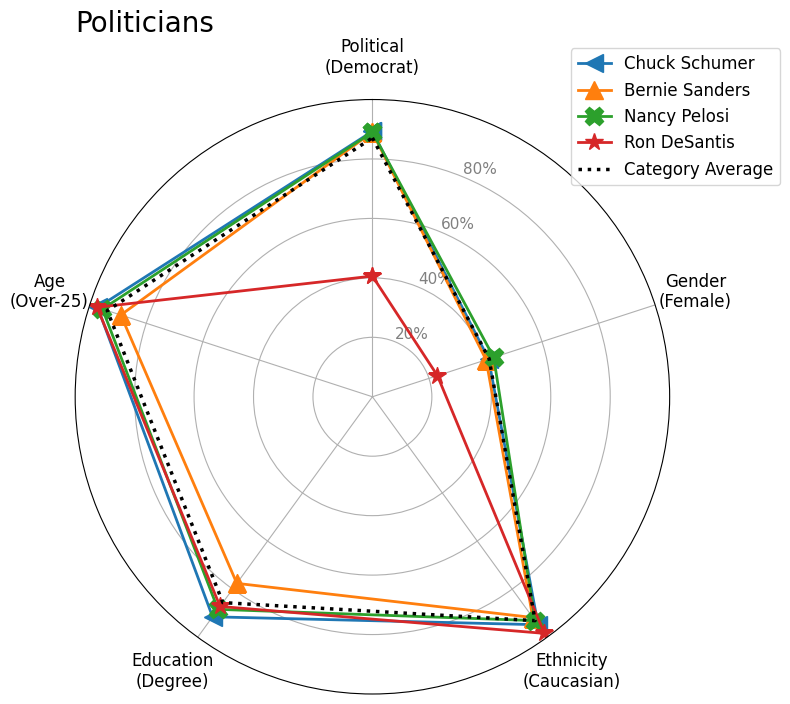

In [ ]:
data = {
    'SenSchumer':	[0.893,	0.411,	0.948,	0.915,	0.972],
    'BernieSanders':	[0.89,	0.402,	0.918,	0.776,	0.89],
    'SpeakerPelosi':	[0.89,	0.429,	0.931,	0.884,	0.955],
    'GovRonDeSantis':	[0.406,	0.23,	0.984,	0.872,	0.974],
    'ALL':	[0.871,	0.413,	0.931,	0.856,	0.938],
    }

category_name = "Politicians"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'SenSchumer': 'Chuck Schumer', 'BernieSanders': 'Bernie Sanders', 
               'SpeakerPelosi': 'Nancy Pelosi', 'GovRonDeSantis': 'Ron DeSantis', 
                'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot(data, category_name, get_name_from_mapping)

File Saved


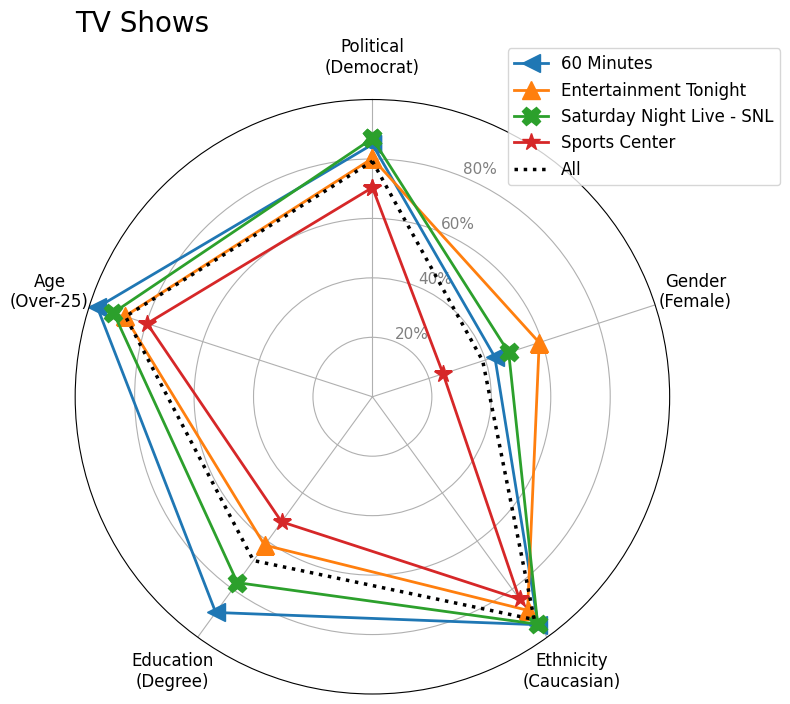

In [ ]:
data = {
    '60Minutes':	[0.849,	0.433,	0.948,	0.897,	0.973],
    'etnow':	[0.802,	0.59,	0.888,	0.617,	0.876],
    'nbcsnl':	[0.869,	0.482,	0.946,	0.773,	0.916],
    'SportsCenter':	[0.704,	0.25,	0.842,	0.52,	0.797],
    'All':	[0.7924,	0.39025,	0.92645,	0.6811,	0.8733],
    }

category_name = "TV Shows"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'60Minutes': '60 Minutes', 'etnow': 'Entertainment Tonight', 
               'nbcsnl': 'Saturday Night Live - SNL', 'SportsCenter': 'Sports Center', 
                'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot(data, category_name, get_name_from_mapping)

File Saved


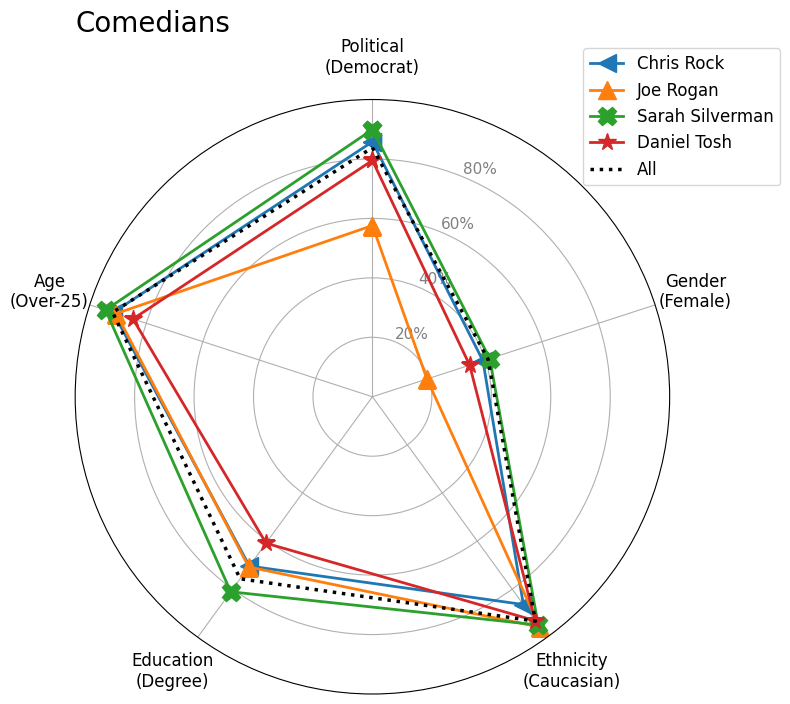

In [ ]:
data = {
    'chrisrock':	[0.858,	0.391,	0.864,	0.704,	0.917],
    'joerogan':	[0.576,	0.193,	0.958,	0.708,	0.906],
    'SarahKSilverman':	[0.899,	0.415,	0.949,	0.811,	0.944],
    'danieltosh':	[0.795,	0.344,	0.931,	0.609,	0.847],
    'All':	[0.838,	0.409,	0.933,	0.757,	0.919],
    }

category_name = "Comedians"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'chrisrock': 'Chris Rock', 
               'joerogan': 'Joe Rogan', 
               'SarahKSilverman': 'Sarah Silverman',
               'danieltosh': 'Daniel Tosh', 
                'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot(data, category_name, get_name_from_mapping)

File Saved


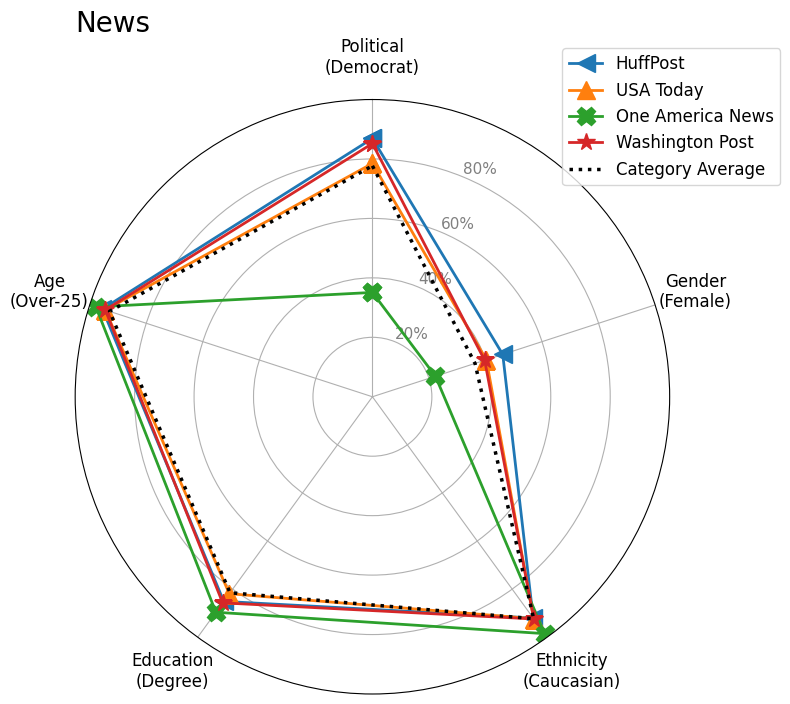

In [ ]:
data = {
    'HuffPost':	[0.869,	0.461,	0.92,	0.851,	0.955],
    'USATODAY':	[0.785,	0.403,	0.923,	0.819,	0.945],
    'OANN':	[0.351,	0.223,	0.985,	0.896,	0.978],
    'washingtonpost':	[0.852,	0.397,	0.924,	0.857,	0.945],
    'ALL':	[0.777,	0.363,	0.923,	0.815,	0.93],
    }

category_name = "News"

def get_name_from_mapping(account_name):
    # This represents your external logic/lookup
    mapping = {'HuffPost': 'HuffPost', 
               'USATODAY': 'USA Today', 
               'OANN': 'One America News',
               'washingtonpost': 'Washington Post', 
                'ALL': 'Category Average'}
    return mapping.get(account_name, account_name)

create_manual_radar_plot(data, category_name, get_name_from_mapping)